# Protein-structure view of the Chimera disagreement signal

*A structural-biology companion to notebooks 04 / 05 / 06 / 08.
For a curated set of genes whose α / Δα signal is biologically
interesting, fetch ortholog protein sequences across our
four-species registry (Human → Macaque → Mouse → Zebrafish),
align them position-wise, project per-residue conservation onto
the human protein's AlphaFold structure, and connect the
structural pattern back to the Chimera-level integration call.*

## Why this exists

Notebooks 04 / 05 / 06 / 08 work at the *gene* level: each gene
gets one α, one Δα, one prior, one categorical tag (M flag,
F flag, robust, …). What they don't show is the *intra-protein
distribution of cross-species variation*. A "high prior" gene with
`mean identity ≈ 0.85` could be 85% identical *uniformly along the
protein* (a steady evolutionary clock), or it could be 100%
identical over a 200-residue catalytic core and 50% identical
over a 100-residue regulatory tail (rapidly evolving subset on
top of a frozen core). The α / Δα signal *cannot distinguish*
these two cases — but they differ biologically, and a paper
should be able to show which is which.

This notebook shows the per-residue cross-species pattern for a
handful of genes whose Chimera signal is a paper headline. For
each gene we deliver:

1. **A multi-species per-residue identity track** (paper-grade
   static figure): one row per species, x = residue index, color
   = `1` if the aligned residue matches human, else `0`. Plus a
   running mean-identity track at the top. Reads as a *bar code*
   of where in the protein the divergence sits.
2. **An interactive 3D rendering of the human AlphaFold
   structure**, cartoon-coloured by mean cross-species
   conservation at each residue. Saved as standalone HTML
   under `notebooks/figures/protein_structure/3d/<gene>.html` and
   embedded in the notebook for inline interaction.
3. **A side-by-side composite** showing the curated set in one
   figure, ordered by Chimera direction (M flag → reference →
   F flag). The disagreement is no longer abstract — the reader
   sees the same gene's α/Δα number in §B and the structural
   reason for it in this figure.

## The gene curation

A broad candidate set (~70 famous textbook genes spanning the
Chimera signal regimes — M-flag metabolic / mtDNA / urea-cycle
enzymes, F-flag developmental / signaling TFs and kinases, and
near-diagonal cytoskeletal / housekeeping references) is then
**filtered to proteins where the trained GIN's per-feature
attribution puts at least 40% of its weight on the ESM-2 PC
channel**. This selects for genes whose Chimera call is genuinely
*driven by the protein-language signal* (rather than being
dominated by expression statistics or sequence-identity scalars),
which is the prerequisite for the structural-biology view this
notebook builds.

The filter is enforced in §B.2 by running captum Integrated
Gradients on the trained GIN at each candidate gene and keeping
only those with `esm2_pc_frac ≥ 0.40`. The remaining set is the
one this notebook plots — typically 20–40 genes spanning all three
direction classes.

## Visual contract

Single grayscale palette throughout (paper-grade, color-blind safe).
The sequence-identity bar code is tuned so the *match* (the bulk
of any conserved protein) is the lightest tone — visually quiet —
and *mismatches* pop as the darkest cells:

- **very light gray** (almost white) → match (residue agrees
  with the human reference at that position),
- **dark gray** → mismatch (residue differs in that species),
- **mid gray** → gap in the alignment (this species' ortholog
  lacks a residue corresponding to the human position).

Per-residue continuous tracks use the same dark / light contrast
to encode sign: dark fill = positive, light fill = negative.

Direction tags (M / F / ref) are encoded in title text shading
plus the categorical letter; the per-residue tracks are
monochromatic.

All visual conventions inherit from `_figure_design.py` (no
grids, no top/right spines, single typeface, vector PDF
output).


## §A.1 — Imports and design system


In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from Bio import Align

# Notebook folder: $CHIMERA_ROOT/notebooks if set, else located from the working directory.
import os
NB_DIR = (Path(os.environ["CHIMERA_ROOT"]) / "notebooks" if os.environ.get("CHIMERA_ROOT")
          else Path.cwd() if (Path.cwd() / "_figure_design.py").exists()
          else Path.cwd() / "notebooks")
assert (NB_DIR / "_figure_design.py").exists(), f"no notebooks folder at {NB_DIR}; set CHIMERA_ROOT"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import _figure_design as fd
import _paper_utils as pu

fd.apply_design()

REPO_ROOT = NB_DIR.parent
RUNS_ROOT = REPO_ROOT / "training" / "runs"
DATA_ROOT = REPO_ROOT / "data" / "processed"
CACHE_DIR = NB_DIR / "cache" / "protein_structure"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = fd.set_figure_dir(NB_DIR / "figures" / "protein_structure")
HTML_DIR = NB_DIR / "figures" / "protein_structure" / "3d"
HTML_DIR.mkdir(parents=True, exist_ok=True)
print(f"figures will be written to: {FIG_DIR}")
print(f"3D HTML embeds will be written to: {HTML_DIR}")
print(f"per-resource cache: {CACHE_DIR}")


figures will be written to: /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure
3D HTML embeds will be written to: /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure/3d
per-resource cache: /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/cache/protein_structure


## §B — Gene registry (candidate pool)

A broad candidate pool of ~70 famous textbook genes spanning the
Chimera signal regimes. Each row records the gene name, expected
direction class (M / F / ref) and the anchor Chimera dataset on
which we look up its Chimera signal. Filtering by HVG presence
happens in §B.1 and by ESM-2 PC attribution fraction in §B.2.


In [2]:
SPECIES = ["hsapiens", "mmulatta", "mmusculus", "drerio"]
SPECIES_LABEL = {
    "hsapiens":  "Human",
    "mmulatta":  "Macaque",
    "mmusculus": "Mouse",
    "drerio":    "Zebrafish",
}
SPECIES_GRAY = {
    "hsapiens":  "#222222",
    "mmulatta":  "#555555",
    "mmusculus": "#888888",
    "drerio":    "#bbbbbb",
}

CANDIDATE_GENES = [
    # ===== M-flag candidates (high prior, expression-divergent) =====
    # Krebs / urea cycle / amino-acid metabolism
    ("GOT1",       "M",   "panc_hmonkey", "Glutamate-oxaloacetate transaminase. Krebs cycle / cancer metabolism."),
    ("GOT2",       "M",   "panc_hmonkey", "Mitochondrial glutamate-oxaloacetate transaminase."),
    ("ASL",        "M",   "panc_hmonkey", "Argininosuccinate lyase. Urea cycle (argininosuccinic aciduria)."),
    ("ASS1",       "M",   "panc_hmonkey", "Argininosuccinate synthase 1. Urea cycle."),
    ("CPS1",       "M",   "panc_4sp",     "Carbamoyl phosphate synthetase I. Urea cycle (CPS1 deficiency)."),
    ("OTC",        "M",   "panc_hmonkey", "Ornithine transcarbamylase. X-linked urea-cycle disease."),
    ("ARG1",       "M",   "panc_hmonkey", "Arginase 1. Urea cycle / immunometabolism."),
    ("PAH",        "M",   "panc_hmonkey", "Phenylalanine hydroxylase. Phenylketonuria (OMIM 261600)."),
    ("AGXT",       "M",   "panc_hmonkey", "Alanine-glyoxylate aminotransferase. Hyperoxaluria type 1."),
    ("GLUL",       "M",   "panc_hmonkey", "Glutamine synthetase. Nitrogen metabolism."),
    # Energy metabolism / gluconeogenesis
    ("PCK1",       "M",   "panc_hmonkey", "PEP carboxykinase, cytosolic. Gluconeogenesis."),
    ("PCK2",       "M",   "panc_hmonkey", "PEP carboxykinase, mitochondrial."),
    ("PDK4",       "M",   "panc_hmonkey", "Pyruvate dehydrogenase kinase 4. Diabetes / fasting."),
    ("ALDOB",      "M",   "panc_hmonkey", "Aldolase B. Hereditary fructose intolerance."),
    ("FBP1",       "M",   "panc_hmonkey", "Fructose-1,6-bisphosphatase 1."),
    ("G6PC",       "M",   "panc_hmonkey", "Glucose-6-phosphatase. Type-Ia GSD."),
    ("GCK",        "M",   "panc_hmonkey", "Glucokinase. MODY2."),
    # Folate / one-carbon
    ("ALDH1L1",    "M",   "panc_hmonkey", "10-formyltetrahydrofolate dehydrogenase. Folate cycle."),
    ("MTHFR",      "M",   "panc_hmonkey", "Methylenetetrahydrofolate reductase."),
    ("BHMT",       "M",   "panc_hmonkey", "Betaine-homocysteine methyltransferase."),
    # mtDNA-encoded
    ("MT-CO1",     "M",   "panc_hmonkey", "Cytochrome c oxidase 1 (mtDNA). Species-barcoding gene."),
    ("MT-CO2",     "M",   "panc_hmonkey", "Cytochrome c oxidase 2 (mtDNA)."),
    ("MT-CO3",     "M",   "panc_hmonkey", "Cytochrome c oxidase 3 (mtDNA)."),
    ("MT-ATP6",    "M",   "panc_hmonkey", "ATP synthase F0 subunit 6 (mtDNA)."),
    ("MT-ATP8",    "M",   "panc_hmonkey", "ATP synthase F0 subunit 8 (mtDNA)."),
    ("MT-CYB",     "M",   "panc_hmonkey", "Cytochrome b (mtDNA)."),
    ("MT-ND1",     "M",   "panc_hmonkey", "NADH dehydrogenase 1 (mtDNA)."),
    ("MT-ND2",     "M",   "panc_hmonkey", "NADH dehydrogenase 2 (mtDNA)."),
    ("MT-ND4",     "M",   "panc_hmonkey", "NADH dehydrogenase 4 (mtDNA)."),
    # Lipid / β-ox
    ("HADHA",      "M",   "panc_hmonkey", "Hydroxyacyl-CoA dehydrogenase α. Fatty-acid β-ox."),
    ("ACADM",      "M",   "panc_hmonkey", "Acyl-CoA dehydrogenase, medium-chain. MCAD deficiency."),
    # GABA / chaperones / β-cell TFs
    ("ABAT",       "M",   "panc_hmonkey", "GABA aminotransferase."),
    ("FKBP5",      "M",   "panc_hmonkey", "FK506-binding protein 5. Steroid response."),
    ("ZBTB20",     "M",   "panc_hmonkey", "ZBTB20 zinc-finger TF. KO → diabetes."),
    # Cancer drivers / regulators
    ("BRAF",       "M",   "panc_hmonkey", "B-Raf kinase. Cancer driver."),
    ("APC",        "M",   "panc_hmonkey", "Adenomatous polyposis coli."),
    ("IDO1",       "M",   "panc_hmonkey", "Indoleamine 2,3-dioxygenase 1. Tryptophan / cancer immunology."),
    ("RORA",       "M",   "panc_hmonkey", "RAR-related orphan receptor α."),
    ("BCAT1",      "M",   "panc_hmonkey", "Branched-chain amino-acid transaminase 1."),

    # ===== F-flag candidates (low prior, integration-aligned) =====
    ("CFTR",       "F",   "panc_hmonkey", "Cystic fibrosis. Drug target (ivacaftor, lumacaftor)."),
    ("MET",        "F",   "panc_hmonkey", "HGF receptor TK. Cancer drug target."),
    ("HNF4A",      "F",   "panc_hmonkey", "MODY1 TF."),
    ("KIT",        "F",   "panc_hmonkey", "KIT receptor TK. GIST / mast-cell."),
    ("GATA4",      "F",   "panc_hmonkey", "GATA4 TF. Cardiac / endoderm."),
    ("GATA6",      "F",   "panc_hmonkey", "GATA6 TF. Pancreas development."),
    ("RUNX1",      "F",   "panc_hmonkey", "RUNX1 TF. AML."),
    ("EGFR",       "F",   "panc_hmonkey", "EGFR receptor TK."),
    ("RET",        "F",   "panc_hmonkey", "RET receptor TK. MEN2 / Hirschsprung."),
    ("FOXA1",      "F",   "panc_hmonkey", "FOXA1 TF. Endoderm."),
    ("FOXA2",      "F",   "panc_hmonkey", "FOXA2 TF. Pancreas / liver."),
    ("PDX1",       "F",   "panc_hmonkey", "Pancreatic & duodenal homeobox 1. β-cell master TF."),
    ("NKX6-1",     "F",   "panc_hmonkey", "NKX6-1 TF. β-cell."),
    ("NKX2-2",     "F",   "panc_hmonkey", "NKX2-2 TF."),
    ("PAX4",       "F",   "panc_hmonkey", "PAX4 TF. β-cell development."),
    ("PAX6",       "F",   "panc_hmonkey", "PAX6 TF. Aniridia."),
    ("ISL1",       "F",   "panc_hmonkey", "ISL1 TF."),
    ("MNX1",       "F",   "panc_hmonkey", "MNX1 TF. Currarino syndrome."),
    ("NEUROG3",    "F",   "panc_hmonkey", "Neurogenin 3. Endocrine progenitor."),
    ("RFX6",       "F",   "panc_hmonkey", "RFX6 TF. Mitchell-Riley syndrome."),
    ("SOX9",       "F",   "panc_hmonkey", "SOX9 TF. Skeletal / pancreatic."),
    ("NOTCH1",     "F",   "panc_hmonkey", "NOTCH1. Cell-fate signaling."),
    ("JAK2",       "F",   "panc_hmonkey", "JAK2. Myeloproliferative."),
    ("PIK3C2G",    "F",   "panc_hmonkey", "PIK3C2G. PI3K class-II."),

    # ===== Reference (near-diagonal, expected low PC fraction) =====
    ("TUBB",       "ref", "panc_hmonkey", "β-tubulin reference."),
    ("TUBA1A",     "ref", "panc_hmonkey", "α-tubulin 1A reference."),
    ("TUBA1B",     "ref", "panc_hmonkey", "α-tubulin 1B reference."),
    ("ACTB",       "ref", "panc_hmonkey", "β-actin reference."),
    ("GAPDH",      "ref", "panc_hmonkey", "GAPDH reference."),
    ("B2M",        "ref", "panc_hmonkey", "β-2-microglobulin reference."),
    ("HPRT1",      "ref", "panc_hmonkey", "HPRT1 reference."),
    ("HSPA5",      "ref", "panc_hmonkey", "HSPA5 / BiP ER chaperone reference."),
    ("HSP90AA1",   "ref", "panc_hmonkey", "HSP90α reference."),
    ("HSP90AB1",   "ref", "panc_hmonkey", "HSP90β reference."),
    ("MAFA",       "ref", "panc_hmonkey", "MAFA β-cell TF (near-diagonal)."),
    ("MAFB",       "ref", "panc_hmonkey", "MAFB α-cell TF (near-diagonal)."),
    ("NEUROD1",    "ref", "panc_hmonkey", "NEUROD1 TF (near-diagonal)."),
    ("CDK1",       "ref", "panc_hmonkey", "CDK1 cell-cycle (near-diagonal)."),
    ("CDK4",       "ref", "panc_hmonkey", "CDK4 cell-cycle (near-diagonal)."),
    ("MTOR",       "ref", "panc_hmonkey", "mTOR kinase (near-diagonal)."),
    ("AKT3",       "ref", "panc_hmonkey", "AKT3 kinase (near-diagonal)."),
    ("MEIS1",      "ref", "panc_hmonkey", "MEIS1 TF (near-diagonal)."),
    ("ONECUT1",    "ref", "panc_hmonkey", "HNF6 / ONECUT1 TF (near-diagonal)."),
]
# Direction encoded as grayscale shade (M = darkest, F = mid, ref = light)
DIRECTION_COLOR = {"M": "#222222", "F": "#666666", "ref": "#aaaaaa"}
# Track / panel grayscale palette
GRAY_DARK = "#222222"
GRAY_MID  = "#666666"
GRAY_LITE = "#aaaaaa"
GRAY_VLITE = "#dddddd"
GRAY_BG   = "#f0f0f0"
CANDIDATES_DF = pd.DataFrame(CANDIDATE_GENES,
                              columns=["gene","direction","dataset","note"])
print(f"candidate pool: {len(CANDIDATES_DF)} genes")
print(CANDIDATES_DF["direction"].value_counts().to_string())


candidate pool: 82 genes
direction
M      39
F      24
ref    19


### §B.1 — Chimera signal lookup per gene + HVG filter

For each candidate gene, pull α / prior / Δα and the §08 QC tag
from the relevant dataset's `final_state.npz` + ortholog table.
Genes that aren't HVGs in their anchor dataset are dropped — they
have no Chimera signal to interpret.


In [3]:
DATASETS = {
    "panc_hmonkey":  {"name": "iter90-150ep-s42",
                      "adata": "camex_human_monkey.h5ad"},
    "panc_4sp":      {"name": "xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42",
                      "adata": "camex_pancreas_unified.h5ad"},
}


def _find_orthos_id(gene_name: str) -> str | None:
    m = ORTHO[ORTHO["hsapiens_gene_name"] == gene_name]
    if not len(m):
        return None
    # ortholog_group_id is the index of ORTHO (set by pu.load_ortholog_table())
    og_id = int(m.index[0])
    return f"ortho_{og_id}"


# Cache var_names + final_state per dataset to avoid re-reading them many times.
import anndata as ad
_DSCACHE: dict[str, dict] = {}
def _load_ds(ds_key: str) -> dict:
    if ds_key in _DSCACHE: return _DSCACHE[ds_key]
    info = DATASETS[ds_key]
    rundir = RUNS_ROOT / info["name"]
    fs = dict(np.load(rundir / "final_state.npz", allow_pickle=False))
    a = ad.read_h5ad(DATA_ROOT / info["adata"], backed="r")
    var_names = list(a.var_names)
    gf_all = np.asarray(a.varm["gene_features"]).astype(np.float32)
    prior_var = np.asarray(a.var["conservation_prior"]).astype(np.float32)
    a.file.close()
    _DSCACHE[ds_key] = {"fs": fs, "var_names": var_names,
                          "gene_features": gf_all, "prior_var": prior_var,
                          "rundir": rundir}
    return _DSCACHE[ds_key]


def chimera_signal(gene: str, ds_key: str) -> dict:
    d = _load_ds(ds_key)
    ortho_id = _find_orthos_id(gene)
    if ortho_id is None or ortho_id not in d["var_names"]:
        return {"alpha": np.nan, "prior": np.nan, "delta_alpha": np.nan,
                "S_g_ema": np.nan, "residual_rms": np.nan,
                "var_name": ortho_id, "row_idx": -1}
    i = d["var_names"].index(ortho_id)
    fs = d["fs"]
    return {
        "var_name":     ortho_id,
        "alpha":        float(fs["alpha"][i]),
        "prior":        float(fs["prior"][i]),
        "delta_alpha":  float(fs["alpha"][i] - fs["prior"][i]),
        "S_g_ema":      float(fs["S_g_ema"][i]),
        "residual_rms": float(fs["residual_rms"][i]),
        "row_idx":      i,
    }


ORTHO = pu.load_ortholog_table("liver")  # every dataset here is a liver cohort
rows = []
for g, dirn, ds, note in CANDIDATE_GENES:
    sig = chimera_signal(g, ds)
    sig.update({"gene": g, "direction": dirn, "dataset": ds, "note": note})
    rows.append(sig)
SIGNAL_ALL = pd.DataFrame(rows).set_index("gene")
SIGNAL = SIGNAL_ALL.dropna(subset=["alpha"]).copy()
n_drop = len(SIGNAL_ALL) - len(SIGNAL)
print(f"HVG filter: kept {len(SIGNAL)} / {len(SIGNAL_ALL)} candidates "
      f"({n_drop} not in HVGs of their anchor dataset).")
print(SIGNAL[["direction","dataset","alpha","prior","delta_alpha"]].to_string(
    float_format=lambda x: f"{x:.3f}"))


HVG filter: kept 54 / 82 candidates (28 not in HVGs of their anchor dataset).
         direction       dataset  alpha  prior  delta_alpha
gene                                                       
GOT1             M  panc_hmonkey  0.031  0.883       -0.852
ASL              M  panc_hmonkey  0.000  0.851       -0.850
CPS1             M      panc_4sp  0.446  0.887       -0.440
OTC              M  panc_hmonkey  0.485  0.847       -0.362
ARG1             M  panc_hmonkey  0.780  0.822       -0.042
PAH              M  panc_hmonkey  0.829  0.846       -0.017
PCK1             M  panc_hmonkey  0.411  0.874       -0.462
PCK2             M  panc_hmonkey  0.860  0.840        0.020
PDK4             M  panc_hmonkey  0.153  0.873       -0.720
ALDOB            M  panc_hmonkey  0.992  0.904        0.088
GCK              M  panc_hmonkey  0.823  0.814        0.009
ALDH1L1          M  panc_hmonkey  0.995  0.882        0.113
MTHFR            M  panc_hmonkey  0.911  0.884        0.027
MT-CO1           M  pa

### §B.2 — Filter to genes whose Chimera call is ESM-2-PC-driven

Run captum Integrated Gradients on the trained GIN at every
HVG-passing candidate, decompose the 72-d attribution by feature
group (ESM-2 PCs, ESM-2 inter-species variance, sequence-identity
stats, expression stats), and keep only genes whose **ESM-2 PC
channel accounts for ≥ 40 % of total |attribution|**. This selects
proteins whose Chimera call is genuinely driven by the protein-
language signal (and is therefore the natural target for the
structure-level decode this notebook builds). Reference housekeeping
genes, whose Chimera signal is dominated by expression statistics,
typically fail this filter — that is by design.

The filter threshold is `MIN_ESM2_PC_FRAC = 0.40`.


In [4]:
import torch
from captum.attr import IntegratedGradients
from chimera._components import GeneIntegrationNetwork

MIN_ESM2_PC_FRAC = 0.40
FEATURE_GROUP = (
    ["esm2_pc"] * 64 + ["esm2_var"] +
    ["seq_id"] + ["expr"] * 3 + ["seq_id"] * 3
)


def _load_gin(ds_key: str) -> GeneIntegrationNetwork:
    ckpt_path = _load_ds(ds_key)["rundir"] / "model" / "model.pt"
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    sd = ckpt["model_state_dict"]
    gin_sd = {k.replace("gin.", "", 1): v for k, v in sd.items()
               if k.startswith("gin.")}
    gin = GeneIntegrationNetwork(n_features=72, n_hidden=32,
                                  n_hidden_layers=2, hidden_activation="tanh")
    gin.load_state_dict(gin_sd); gin.eval()
    return gin

GIN_BY_DATASET = {ds: _load_gin(ds) for ds in DATASETS}


class _CorrWrap(torch.nn.Module):
    def __init__(self, gin): super().__init__(); self.gin = gin
    def forward(self, x): return self.gin.correction_mlp(x).squeeze(-1)


def _esm2_pc_frac(gene: str) -> float:
    sig = SIGNAL.loc[gene]
    ds = sig["dataset"]
    i = int(sig["row_idx"])
    gf = _load_ds(ds)["gene_features"][i]
    gin = GIN_BY_DATASET[ds]
    ig = IntegratedGradients(_CorrWrap(gin))
    x = torch.tensor(gf, dtype=torch.float32).unsqueeze(0)
    attr, _ = ig.attribute(x, baselines=torch.zeros_like(x), n_steps=64,
                            return_convergence_delta=True)
    a = attr.squeeze(0).detach().numpy()
    pc_abs   = float(np.sum(np.abs([a[k] for k, gg in enumerate(FEATURE_GROUP)
                                      if gg == "esm2_pc"])))
    tot_abs  = float(np.sum(np.abs(a))) or 1.0
    return pc_abs / tot_abs


pc_fracs = {g: _esm2_pc_frac(g) for g in SIGNAL.index}
SIGNAL = SIGNAL.assign(esm2_pc_frac=pd.Series(pc_fracs))
KEEP = [g for g in SIGNAL.index if SIGNAL.loc[g, "esm2_pc_frac"] >= MIN_ESM2_PC_FRAC]
GENES = [(g, SIGNAL.loc[g, "direction"], SIGNAL.loc[g, "dataset"],
          SIGNAL.loc[g, "note"]) for g in KEEP]
SIGNAL = SIGNAL.loc[KEEP]
print(f"ESM-2-PC-channel filter (≥ {MIN_ESM2_PC_FRAC:.0%}): "
      f"kept {len(GENES)} / {len(pc_fracs)} HVG-passing candidates.")
print(SIGNAL[["direction","dataset","alpha","prior","delta_alpha",
              "esm2_pc_frac"]].sort_values("esm2_pc_frac",
                                            ascending=False).to_string(
    float_format=lambda x: f"{x:.3f}"))
# Persist selected list so notebook 10 (or any downstream script) can
# adopt the same filtered registry without re-running attribution.
SHARED_DIR = NB_DIR / "cache" / "gin_attribution"
SHARED_DIR.mkdir(parents=True, exist_ok=True)
(SHARED_DIR / "selected_genes.json").write_text(json.dumps(
    [{"gene": g, "direction": d, "dataset": ds, "note": n,
      "esm2_pc_frac": float(SIGNAL.loc[g, "esm2_pc_frac"])}
     for g, d, ds, n in GENES], indent=2))
print(f"\nselected gene list cached to: {SHARED_DIR / 'selected_genes.json'}")


ESM-2-PC-channel filter (≥ 40%): kept 14 / 54 HVG-passing candidates.
       direction       dataset  alpha  prior  delta_alpha  esm2_pc_frac
gene                                                                   
GATA6          F  panc_hmonkey  0.855  0.780        0.075         0.815
FOXA2          F  panc_hmonkey  0.866  0.869       -0.003         0.676
GATA4          F  panc_hmonkey  0.922  0.794        0.128         0.675
MAFB         ref  panc_hmonkey  0.915  0.886        0.029         0.672
PCK2           M  panc_hmonkey  0.860  0.840        0.020         0.663
HPRT1        ref  panc_hmonkey  0.943  0.950       -0.007         0.588
MEIS1        ref  panc_hmonkey  0.989  0.950        0.039         0.574
MT-ND2         M  panc_hmonkey  0.399  0.582       -0.183         0.501
RUNX1          F  panc_hmonkey  0.981  0.869        0.112         0.464
HSPA5        ref  panc_hmonkey  0.941  0.950       -0.009         0.456
FOXA1          F  panc_hmonkey  0.866  0.850        0.015         

## §C — Fetch ortholog protein sequences and AlphaFold structures

ENSEMBL and AlphaFold REST APIs.  Everything goes through an
on-disk cache under
`notebooks/cache/protein_structure/` so re-runs are instant.

Per-call rate limit: a 0.05 s sleep between requests is enough
for ENSEMBL's 15 req/s policy and for the AlphaFold service's
headers.  The fetch step is the only network-bound part of the
notebook.


In [5]:
ENSEMBL_REST = "https://rest.ensembl.org"
UNIPROT_REST = "https://rest.uniprot.org"
AFDB_API     = "https://alphafold.ebi.ac.uk/api/prediction"
AFDB_FILES   = "https://alphafold.ebi.ac.uk/files"
HEADERS_J    = {"Content-Type": "application/json"}
HEADERS_FA   = {"Content-Type": "text/x-fasta"}

SEQ_CACHE = CACHE_DIR / "sequences.json"   # {ortholog_id_per_species → fasta}
UNIPROT_CACHE = CACHE_DIR / "uniprot.json"  # {gene_name → uniprot_acc}
PDB_DIR  = CACHE_DIR / "pdbs"
PDB_DIR.mkdir(parents=True, exist_ok=True)


def _load_json(p: Path, default):
    if p.exists():
        try: return json.loads(p.read_text())
        except Exception: return default
    return default


def _save_json(p: Path, obj):
    p.write_text(json.dumps(obj, indent=2))


SEQS    = _load_json(SEQ_CACHE,    {})    # mutated below
UPMAP   = _load_json(UNIPROT_CACHE, {})


def fetch_canonical_protein(ensembl_gene_id: str) -> str:
    if ensembl_gene_id in SEQS:
        return SEQS[ensembl_gene_id]
    time.sleep(0.05)
    r = requests.get(f"{ENSEMBL_REST}/lookup/id/{ensembl_gene_id}?expand=1",
                      headers=HEADERS_J, timeout=30)
    if r.status_code != 200:
        SEQS[ensembl_gene_id] = ""
        return ""
    data = r.json()
    transcripts = data.get("Transcript", [])
    canon = next((t for t in transcripts if t.get("is_canonical")), None)
    if canon is None and transcripts:
        canon = max(transcripts, key=lambda t: t.get("length", 0))
    if canon is None:
        SEQS[ensembl_gene_id] = ""
        return ""
    tid = canon["id"]
    time.sleep(0.05)
    r2 = requests.get(f"{ENSEMBL_REST}/sequence/id/{tid}?type=protein",
                       headers=HEADERS_FA, timeout=30)
    if r2.status_code != 200:
        SEQS[ensembl_gene_id] = ""
        return ""
    seq = "".join(l for l in r2.text.splitlines() if not l.startswith(">"))
    seq = seq.replace("*", "").upper()
    SEQS[ensembl_gene_id] = seq
    _save_json(SEQ_CACHE, SEQS)
    return seq


def fetch_uniprot_acc(gene_name: str) -> str:
    if gene_name in UPMAP and UPMAP[gene_name]:
        return UPMAP[gene_name]
    time.sleep(0.05)
    url = (f"{UNIPROT_REST}/uniprotkb/search?"
           f"query=gene_exact:{gene_name}+AND+organism_id:9606+AND+reviewed:true"
           f"&format=tsv&fields=accession&size=1")
    r = requests.get(url, timeout=30)
    if r.status_code != 200:
        return ""
    lines = [l for l in r.text.strip().splitlines() if l]
    if len(lines) < 2:
        return ""
    acc = lines[1].strip()
    UPMAP[gene_name] = acc
    _save_json(UNIPROT_CACHE, UPMAP)
    return acc


def fetch_alphafold_pdb(uniprot_acc: str) -> Path | None:
    if not uniprot_acc:
        return None
    cached = list(PDB_DIR.glob(f"AF-{uniprot_acc}-F1-model_v*.pdb"))
    if cached:
        return cached[0]
    time.sleep(0.1)
    api = requests.get(f"{AFDB_API}/{uniprot_acc}", timeout=30)
    if api.status_code != 200:
        return None
    meta = api.json()
    if not meta:
        return None
    version = meta[0].get("latestVersion", 4)
    time.sleep(0.1)
    url = f"{AFDB_FILES}/AF-{uniprot_acc}-F1-model_v{version}.pdb"
    r = requests.get(url, timeout=60)
    if r.status_code != 200:
        return None
    path = PDB_DIR / f"AF-{uniprot_acc}-F1-model_v{version}.pdb"
    path.write_text(r.text)
    return path


print("network fetchers ready.")


network fetchers ready.


### §C.1 — Run the fetch loop for the gene registry

For each curated gene, fetch:
- Human + ortholog ENSEMBL gene IDs from the ortholog table
- Canonical protein sequence per species (cached)
- Human UniProt accession (cached)
- Human AlphaFold PDB (cached)


In [6]:
GENE_RECORDS: dict[str, dict] = {}
for g, dirn, ds, note in GENES:
    m = ORTHO[ORTHO["hsapiens_gene_name"] == g]
    if not len(m):
        print(f"  {g}: not in ortholog table — skipping.")
        continue
    rec = {"gene": g, "direction": dirn, "anchor_dataset": ds, "note": note,
           "sequences": {}, "uniprot": "", "pdb": None}
    row = m.iloc[0]
    for sp in SPECIES:
        gid_col = f"{sp}_gene_id"
        gid = row.get(gid_col)
        if pd.isna(gid) or not isinstance(gid, str) or not gid:
            rec["sequences"][sp] = ""
            continue
        seq = fetch_canonical_protein(gid)
        rec["sequences"][sp] = seq
    # Human UniProt accession (for AlphaFold)
    rec["uniprot"] = fetch_uniprot_acc(g)
    rec["pdb"]     = str(fetch_alphafold_pdb(rec["uniprot"]) or "")
    GENE_RECORDS[g] = rec
    lengths = {sp: len(rec["sequences"].get(sp, "")) for sp in SPECIES}
    print(f"  {g:8s}  uniprot={rec['uniprot'] or '?':10s}  pdb={'yes' if rec['pdb'] else 'no':3s}  lengths={lengths}")


  PCK2      uniprot=Q16822      pdb=yes  lengths={'hsapiens': 640, 'mmulatta': 644, 'mmusculus': 640, 'drerio': 636}
  MT-ND2    uniprot=P03891      pdb=yes  lengths={'hsapiens': 347, 'mmulatta': 347, 'mmusculus': 345, 'drerio': 348}
  CFTR      uniprot=P13569      pdb=yes  lengths={'hsapiens': 1480, 'mmulatta': 1489, 'mmusculus': 1476, 'drerio': 1485}
  GATA4     uniprot=P43694      pdb=yes  lengths={'hsapiens': 443, 'mmulatta': 443, 'mmusculus': 442, 'drerio': 352}
  GATA6     uniprot=Q92908      pdb=yes  lengths={'hsapiens': 595, 'mmulatta': 595, 'mmusculus': 589, 'drerio': 501}
  RUNX1     uniprot=Q01196      pdb=yes  lengths={'hsapiens': 480, 'mmulatta': 480, 'mmusculus': 465, 'drerio': 451}
  FOXA1     uniprot=P55317      pdb=yes  lengths={'hsapiens': 472, 'mmulatta': 470, 'mmusculus': 468, 'drerio': 427}
  FOXA2     uniprot=Q9Y261      pdb=yes  lengths={'hsapiens': 463, 'mmulatta': 457, 'mmusculus': 465, 'drerio': 409}
  MNX1      uniprot=P50219      pdb=yes  lengths={'hsapiens'

## §D — Pairwise alignment + per-position conservation

For each gene we have the human canonical protein and one
ortholog protein per species. We pair-align each ortholog
against the **human** sequence (global alignment, BLOSUM62-style
affine gap penalties) and project the alignment back onto the
human residue index, so every visualization shares the same
x-axis (the human protein).

Per-position outputs (one row per species, indexed by human
residue position):

- `match[s, i]` — `1` if the aligned residue in species `s`
  equals the human residue at position `i`; `0` if mismatched;
  `−1` if the alignment introduces a gap there (i.e., that
  species' ortholog has no residue corresponding to human
  position `i`).
- `mean_match[i]` — average across species of `match[s, i]`
  treating gaps as `0` (the canonical "fraction of orthologs
  that conserve human residue `i`"). The 3D rendering colors
  residues by this number.


In [7]:
aligner = Align.PairwiseAligner(scoring="blastp")
aligner.mode = "global"


def project_to_human(seq_h: str, seq_x: str) -> np.ndarray:
    # Returns (L_h,) array: 1 = match, 0 = mismatch, -1 = gap.
    if not seq_x or not seq_h:
        return np.full(len(seq_h), -1, dtype=int)
    aln = aligner.align(seq_h, seq_x)[0]
    # aln.aligned is a tuple of (h_blocks, x_blocks); we walk the alignment string
    a_str = aln.format()
    lines = a_str.split("\n")
    # PairwiseAligner.format() returns "target\nmid\nquery\n" — but for
    # robustness reconstruct from coordinates instead.
    out = np.full(len(seq_h), -1, dtype=int)
    h_blocks, x_blocks = aln.aligned
    for (hs, he), (xs, xe) in zip(h_blocks, x_blocks):
        for k in range(he - hs):
            hp = hs + k; xp = xs + k
            if hp >= len(seq_h) or xp >= len(seq_x):
                continue
            out[hp] = 1 if seq_h[hp] == seq_x[xp] else 0
    return out


PROJECTIONS: dict[str, dict] = {}
for g, rec in GENE_RECORDS.items():
    seq_h = rec["sequences"].get("hsapiens", "")
    if not seq_h:
        print(f"  {g}: no human sequence — skipping projection.")
        continue
    proj = {sp: project_to_human(seq_h, rec["sequences"].get(sp, ""))
            for sp in SPECIES if sp != "hsapiens"}
    # mean conservation across species, treating gaps (−1) as 0
    stack = np.stack([proj[sp].clip(0, 1) for sp in proj], axis=0)
    mean_match = stack.mean(axis=0)
    PROJECTIONS[g] = {"length": len(seq_h),
                       "per_species": proj,
                       "mean_match": mean_match,
                       "human_seq": seq_h}
    print(f"  {g}: L={len(seq_h)}  "
          f"mean cons. = {mean_match.mean():.3f}  "
          f"min cons. = {mean_match.min():.3f}")


  PCK2: L=640  mean cons. = 0.843  min cons. = 0.000
  MT-ND2: L=347  mean cons. = 0.583  min cons. = 0.000
  CFTR: L=1480  mean cons. = 0.774  min cons. = 0.000
  GATA4: L=443  mean cons. = 0.804  min cons. = 0.000
  GATA6: L=595  mean cons. = 0.781  min cons. = 0.000
  RUNX1: L=480  mean cons. = 0.879  min cons. = 0.000
  FOXA1: L=472  mean cons. = 0.858  min cons. = 0.000
  FOXA2: L=463  mean cons. = 0.869  min cons. = 0.333
  MNX1: L=401  mean cons. = 0.807  min cons. = 0.000
  HPRT1: L=218  mean cons. = 0.960  min cons. = 0.333
  HSPA5: L=654  mean cons. = 0.967  min cons. = 0.333
  MAFB: L=323  mean cons. = 0.900  min cons. = 0.333
  CDK1: L=297  mean cons. = 0.932  min cons. = 0.333
  MEIS1: L=390  mean cons. = 0.968  min cons. = 0.333


## §E — Per-residue conservation track plots

One single-panel figure per gene. Top track = mean conservation
(smooth line + filled area); below = three species rows, each
showing match/mismatch/gap as a 1D image. Title bar carries
the Chimera signal (α, prior, Δα) and the §08 direction.


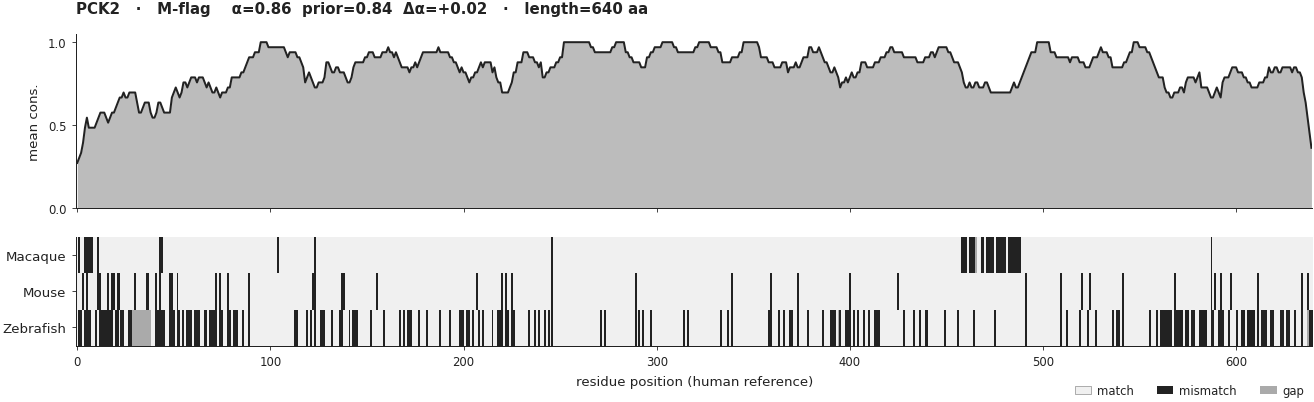

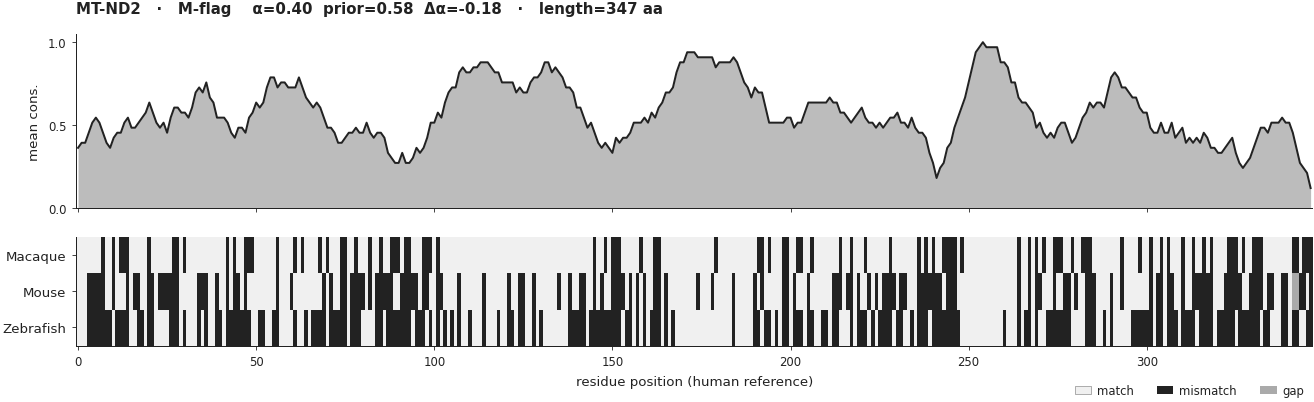

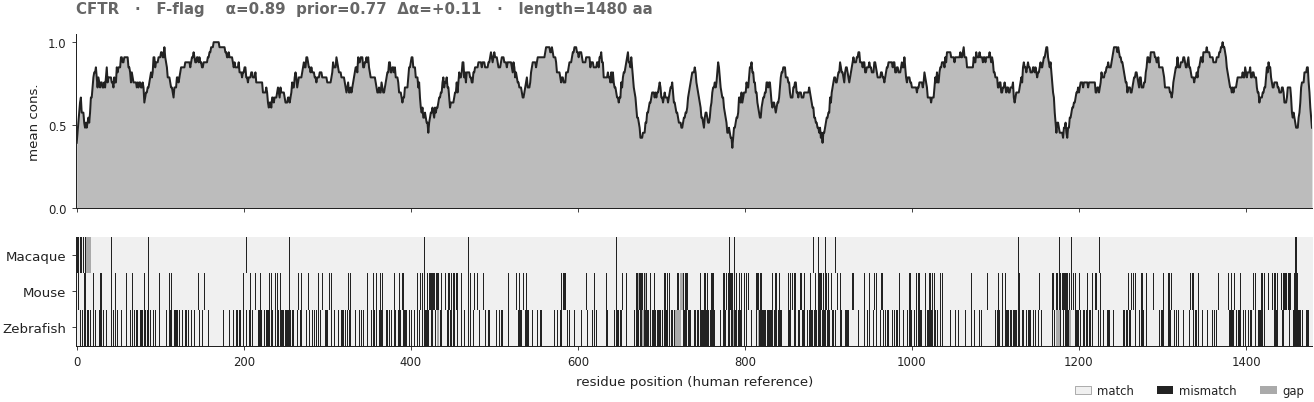

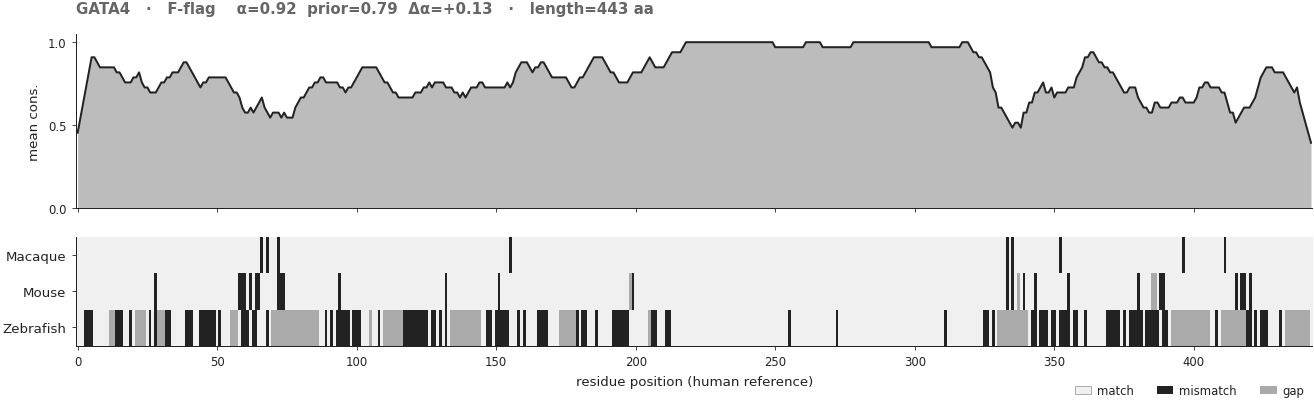

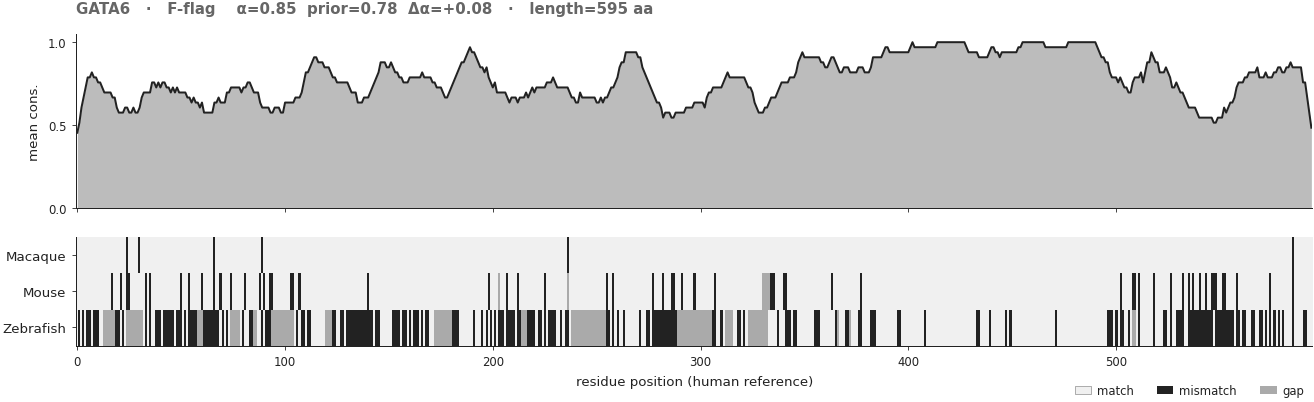

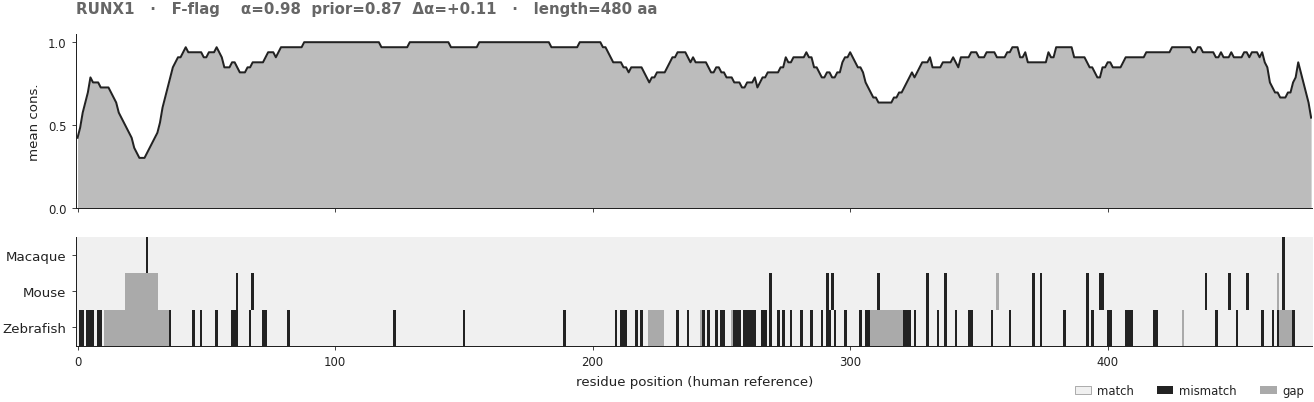

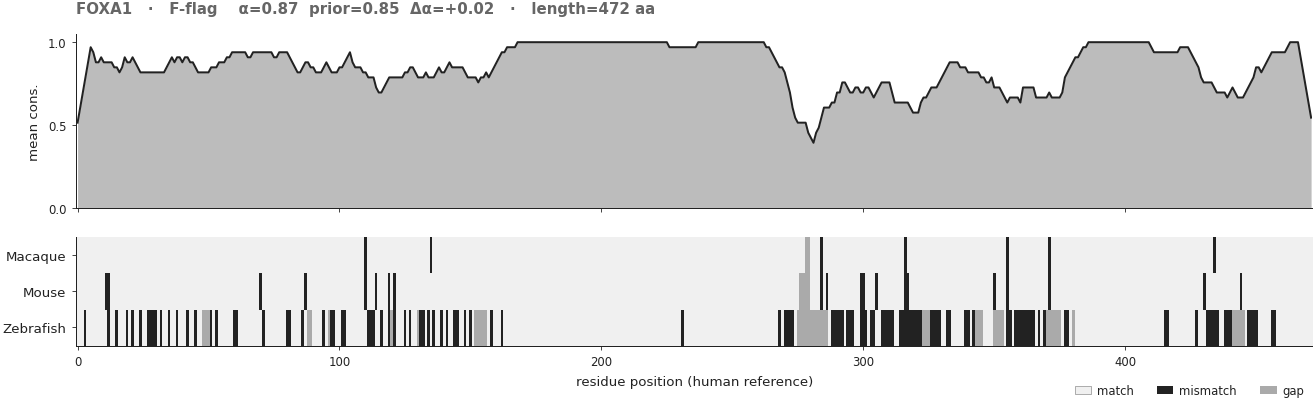

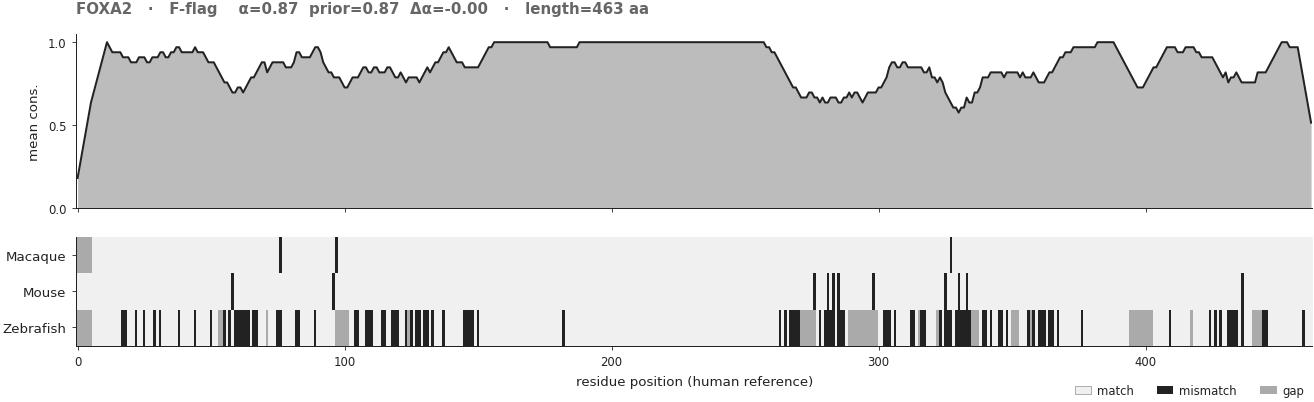

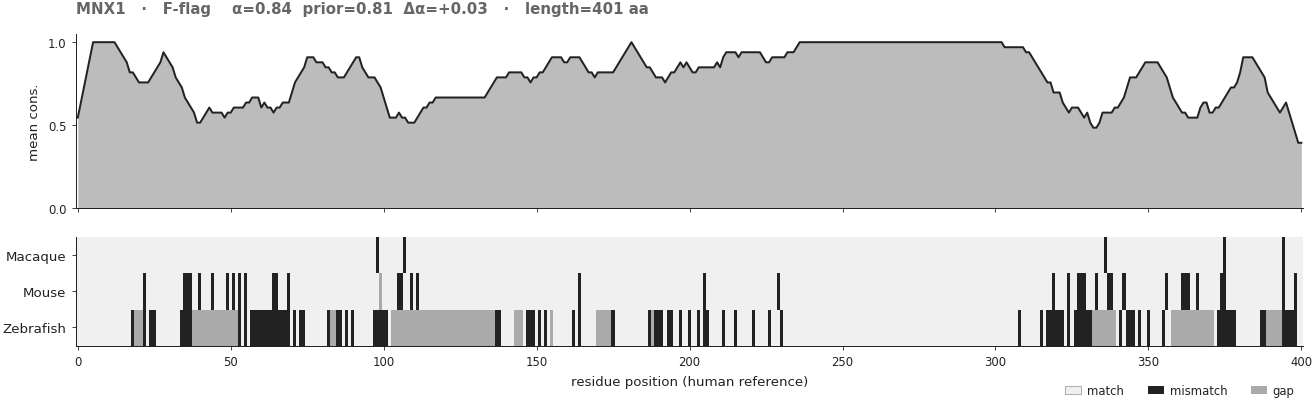

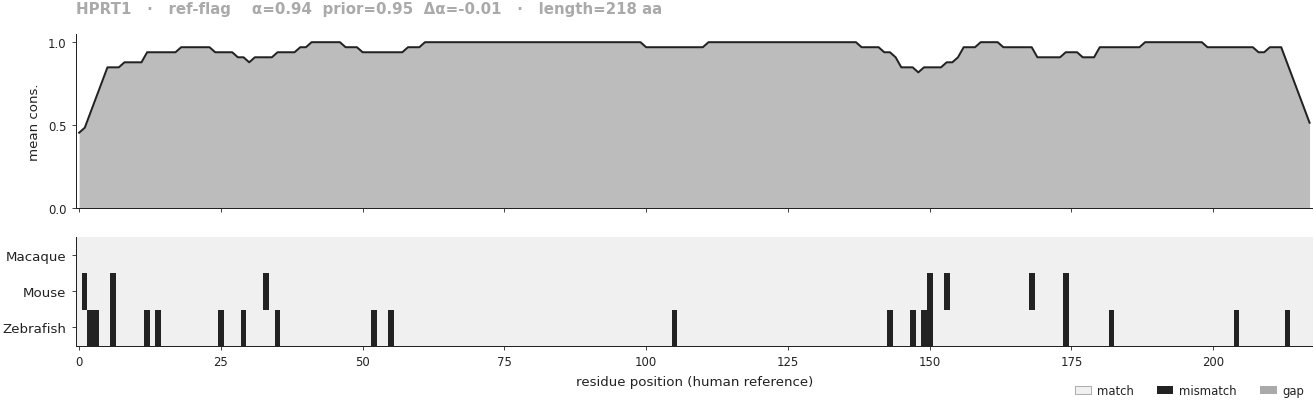

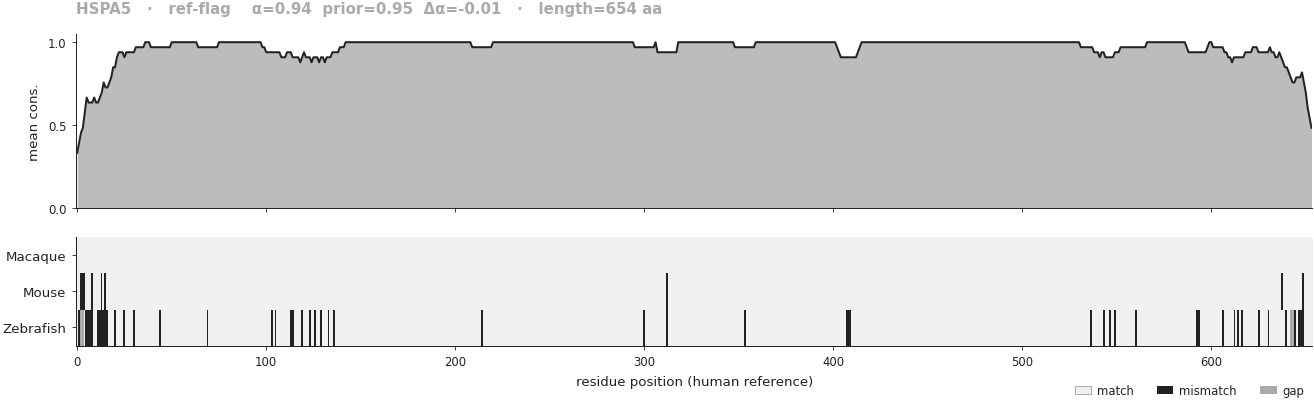

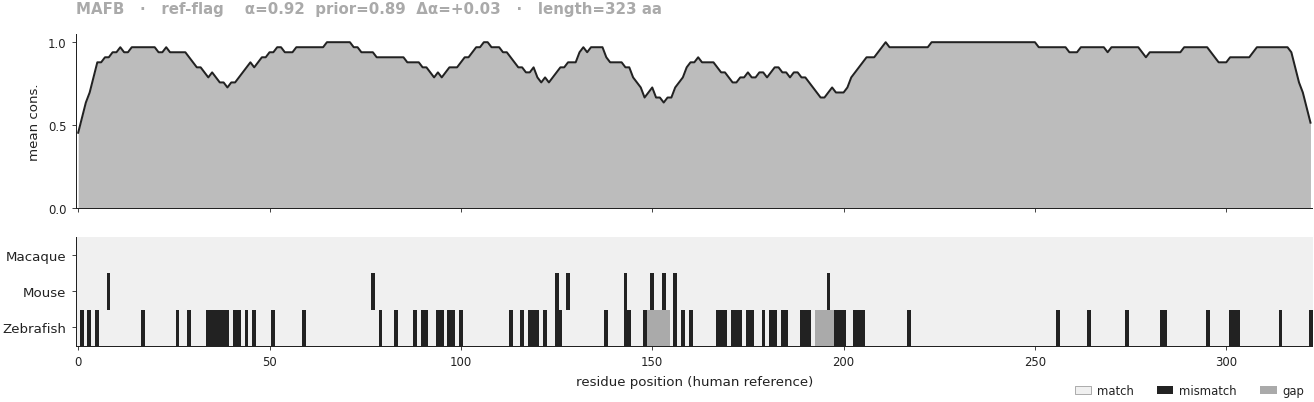

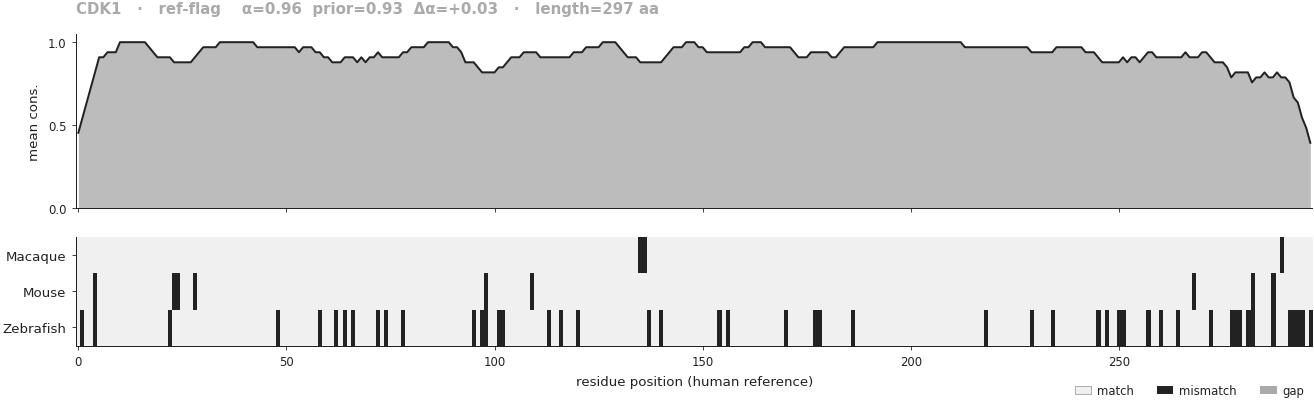

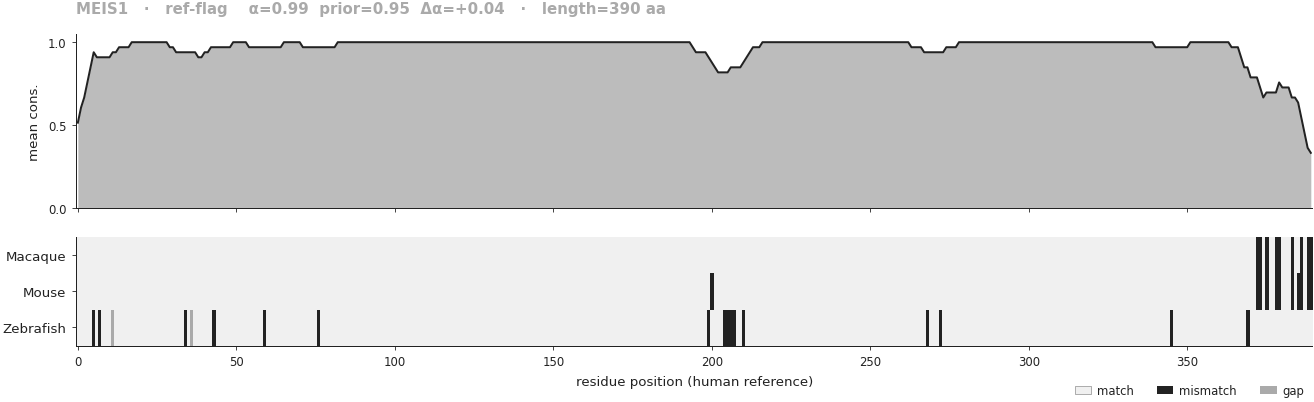

In [8]:
SPECIES_NON_HUMAN = [s for s in SPECIES if s != "hsapiens"]

def plot_conservation_track(g: str, save_name: str):
    rec = GENE_RECORDS[g]; proj = PROJECTIONS.get(g)
    if proj is None:
        print(f"  {g}: no projection — skipping plot."); return
    L = proj["length"]
    mean_match = proj["mean_match"]
    sig = SIGNAL.loc[g]

    fig = plt.figure(figsize=(11.0, 3.4), constrained_layout=True)
    gs = fig.add_gridspec(2, 1, height_ratios=[1.6, 1.0], hspace=0.10)
    ax_top = fig.add_subplot(gs[0])
    ax_bot = fig.add_subplot(gs[1], sharex=ax_top)

    # Top: smoothed mean conservation
    if L >= 11:
        kernel = np.ones(11) / 11.0
        smoothed = np.convolve(mean_match, kernel, mode="same")
    else:
        smoothed = mean_match
    ax_top.fill_between(np.arange(L), 0, smoothed, color=GRAY_DARK,
                         alpha=0.30, linewidth=0)
    ax_top.plot(np.arange(L), smoothed, color=GRAY_DARK, linewidth=1.2)
    ax_top.set_ylim(0, 1.05)
    ax_top.set_yticks([0, 0.5, 1.0])
    ax_top.set_ylabel("mean cons.", fontsize=8)
    ax_top.spines["top"].set_visible(False); ax_top.spines["right"].set_visible(False)
    ax_top.tick_params(labelbottom=False)
    # Title-equivalent annotation (no axes title per design system)
    title = (f"{g}   ·   {SIGNAL.loc[g, 'direction']}-flag  "
             f"  α={sig['alpha']:.2f}  prior={sig['prior']:.2f}  Δα={sig['delta_alpha']:+.2f}"
             f"   ·   length={L} aa")
    ax_top.text(0, 1.10, title, transform=ax_top.transAxes,
                 fontsize=9, ha="left", va="bottom",
                 color=DIRECTION_COLOR.get(sig['direction'], '#222222'),
                 fontweight="bold")

    # Bottom: per-species heatmap (rows = species)
    rows = []
    for sp in SPECIES_NON_HUMAN:
        rows.append(proj["per_species"][sp])
    img = np.vstack(rows).astype(float)
    # Grayscale palette tuned so the *match* (the bulk of any conserved
    # protein) is the lightest tone — visually quiet — and *mismatches*
    # pop as the darkest cells.  Gaps sit at mid gray (rare, but
    # informative when present).
    from matplotlib.colors import ListedColormap
    cmap = ListedColormap([GRAY_LITE, GRAY_DARK, GRAY_BG])  # gap, mismatch, match
    img_idx = (img + 1).astype(int)
    ax_bot.imshow(img_idx, aspect="auto", cmap=cmap, vmin=0, vmax=2,
                   interpolation="nearest")
    ax_bot.set_yticks(range(len(SPECIES_NON_HUMAN)))
    ax_bot.set_yticklabels([SPECIES_LABEL[s] for s in SPECIES_NON_HUMAN], fontsize=8)
    ax_bot.set_xlabel("residue position (human reference)")
    ax_bot.spines["top"].set_visible(False); ax_bot.spines["right"].set_visible(False)

    # tiny inline legend
    from matplotlib.patches import Patch
    leg_handles = [
        Patch(facecolor=GRAY_BG,   edgecolor="#888888", linewidth=0.4, label="match"),
        Patch(facecolor=GRAY_DARK, label="mismatch"),
        Patch(facecolor=GRAY_LITE, label="gap"),
    ]
    ax_bot.legend(handles=leg_handles, loc="lower right", frameon=False,
                   fontsize=7, ncol=3, bbox_to_anchor=(1.0, -0.55))
    fd.save_figure(fig, save_name)
    plt.show()


for g, _, _, _ in GENES:
    if g in GENE_RECORDS and g in PROJECTIONS:
        plot_conservation_track(g, f"E_track__{g}")


## §F — 3D structure: human AlphaFold cartoon, residues colored by mean
cross-species conservation

For each gene with an AlphaFold structure we fetch the cartoon
and color each residue by `mean_match[i]` (0 = divergent → red;
1 = conserved → blue), via py3Dmol's per-residue
`colorByElement` API. The widget renders inline (interactive
rotate / zoom) and we also dump a standalone HTML file under
`notebooks/figures/protein_structure/3d/<gene>.html` so the
same visualization is portable to any browser.

The B-factor channel of the PDB is overwritten with `mean_match`
so a viewer can reproduce the coloring from the PDB alone (with
e.g. PyMOL: `spectrum b, red_white_blue`).


In [9]:
import py3Dmol
from IPython.display import HTML, display


def render_structure(g: str, save_name: str):
    rec = GENE_RECORDS.get(g, {})
    pdb_path = rec.get("pdb")
    proj = PROJECTIONS.get(g)
    if not pdb_path or proj is None:
        print(f"  {g}: no PDB or projection — skipping 3D view."); return None
    pdb_path = Path(pdb_path)
    if not pdb_path.exists():
        print(f"  {g}: PDB cache missing at {pdb_path} — skipping."); return None

    mean_match = proj["mean_match"]
    # Rewrite B-factor with mean_match (rescaled to 0–100 for PDB column width)
    out_lines = []
    b_by_res: dict[int, float] = {}
    for line in pdb_path.read_text().splitlines():
        if line.startswith(("ATOM  ", "HETATM")):
            try:
                res_seq = int(line[22:26].strip())
            except ValueError:
                out_lines.append(line); continue
            idx = res_seq - 1  # PDB residue numbering is 1-based
            if 0 <= idx < len(mean_match):
                b = float(mean_match[idx]) * 100.0
            else:
                b = 50.0
            b_by_res[res_seq] = b
            # B-factor lives in columns 61–66 (1-indexed) → slice [60:66] in Python
            new = line[:60] + f"{b:6.2f}" + line[66:]
            out_lines.append(new)
        else:
            out_lines.append(line)
    rewritten_pdb = "\n".join(out_lines) + "\n"

    view = py3Dmol.view(width=620, height=440)
    view.addModel(rewritten_pdb, "pdb")
    view.setStyle({"cartoon": {"colorscheme": {
        "prop": "b",
        "gradient": "rwb",   # red→white→blue maps low B → red, high B → blue
        "min": 0.0, "max": 100.0,
    }}})
    view.setBackgroundColor("white")
    view.zoomTo()

    # Save standalone HTML
    html_path = HTML_DIR / f"{g}.html"
    with open(html_path, "w") as f:
        f.write(view._make_html())
    print(f"  saved 3D HTML → {html_path}")
    # Display inline
    display(HTML(view._make_html()))
    return view


for g, _, _, _ in GENES:
    sig = SIGNAL.loc[g]
    title_color = DIRECTION_COLOR.get(sig['direction'], '#222222')
    from IPython.display import Markdown
    display(Markdown(f"<h4 style='color:{title_color}'>{g} — "
                     f"{sig['direction']}-flag · α={sig['alpha']:.2f}, "
                     f"prior={sig['prior']:.2f}, Δα={sig['delta_alpha']:+.2f}</h4>"))
    render_structure(g, f"F_3d__{g}")


<h4 style='color:#222222'>PCK2 — M-flag · α=0.86, prior=0.84, Δα=+0.02</h4>

  saved 3D HTML → /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure/3d/PCK2.html


<h4 style='color:#222222'>MT-ND2 — M-flag · α=0.40, prior=0.58, Δα=-0.18</h4>

  saved 3D HTML → /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure/3d/MT-ND2.html


<h4 style='color:#666666'>CFTR — F-flag · α=0.89, prior=0.77, Δα=+0.11</h4>

  saved 3D HTML → /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure/3d/CFTR.html


... (18 outputs left out)

<h4 style='color:#aaaaaa'>CDK1 — ref-flag · α=0.96, prior=0.93, Δα=+0.03</h4>

  saved 3D HTML → /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure/3d/CDK1.html


<h4 style='color:#aaaaaa'>MEIS1 — ref-flag · α=0.99, prior=0.95, Δα=+0.04</h4>

  saved 3D HTML → /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure/3d/MEIS1.html


## §G — Combined comparative figure

Six gene panels in one figure, ordered by Chimera direction
(M flag → reference → F flag), each panel reduced to:

- the smoothed mean-conservation curve (top mini-track),
- a mini per-species heatmap underneath,
- the gene's α / prior / Δα as title.

This is the one-figure summary of *what cross-species sequence
divergence looks like across the Chimera signal regimes*.


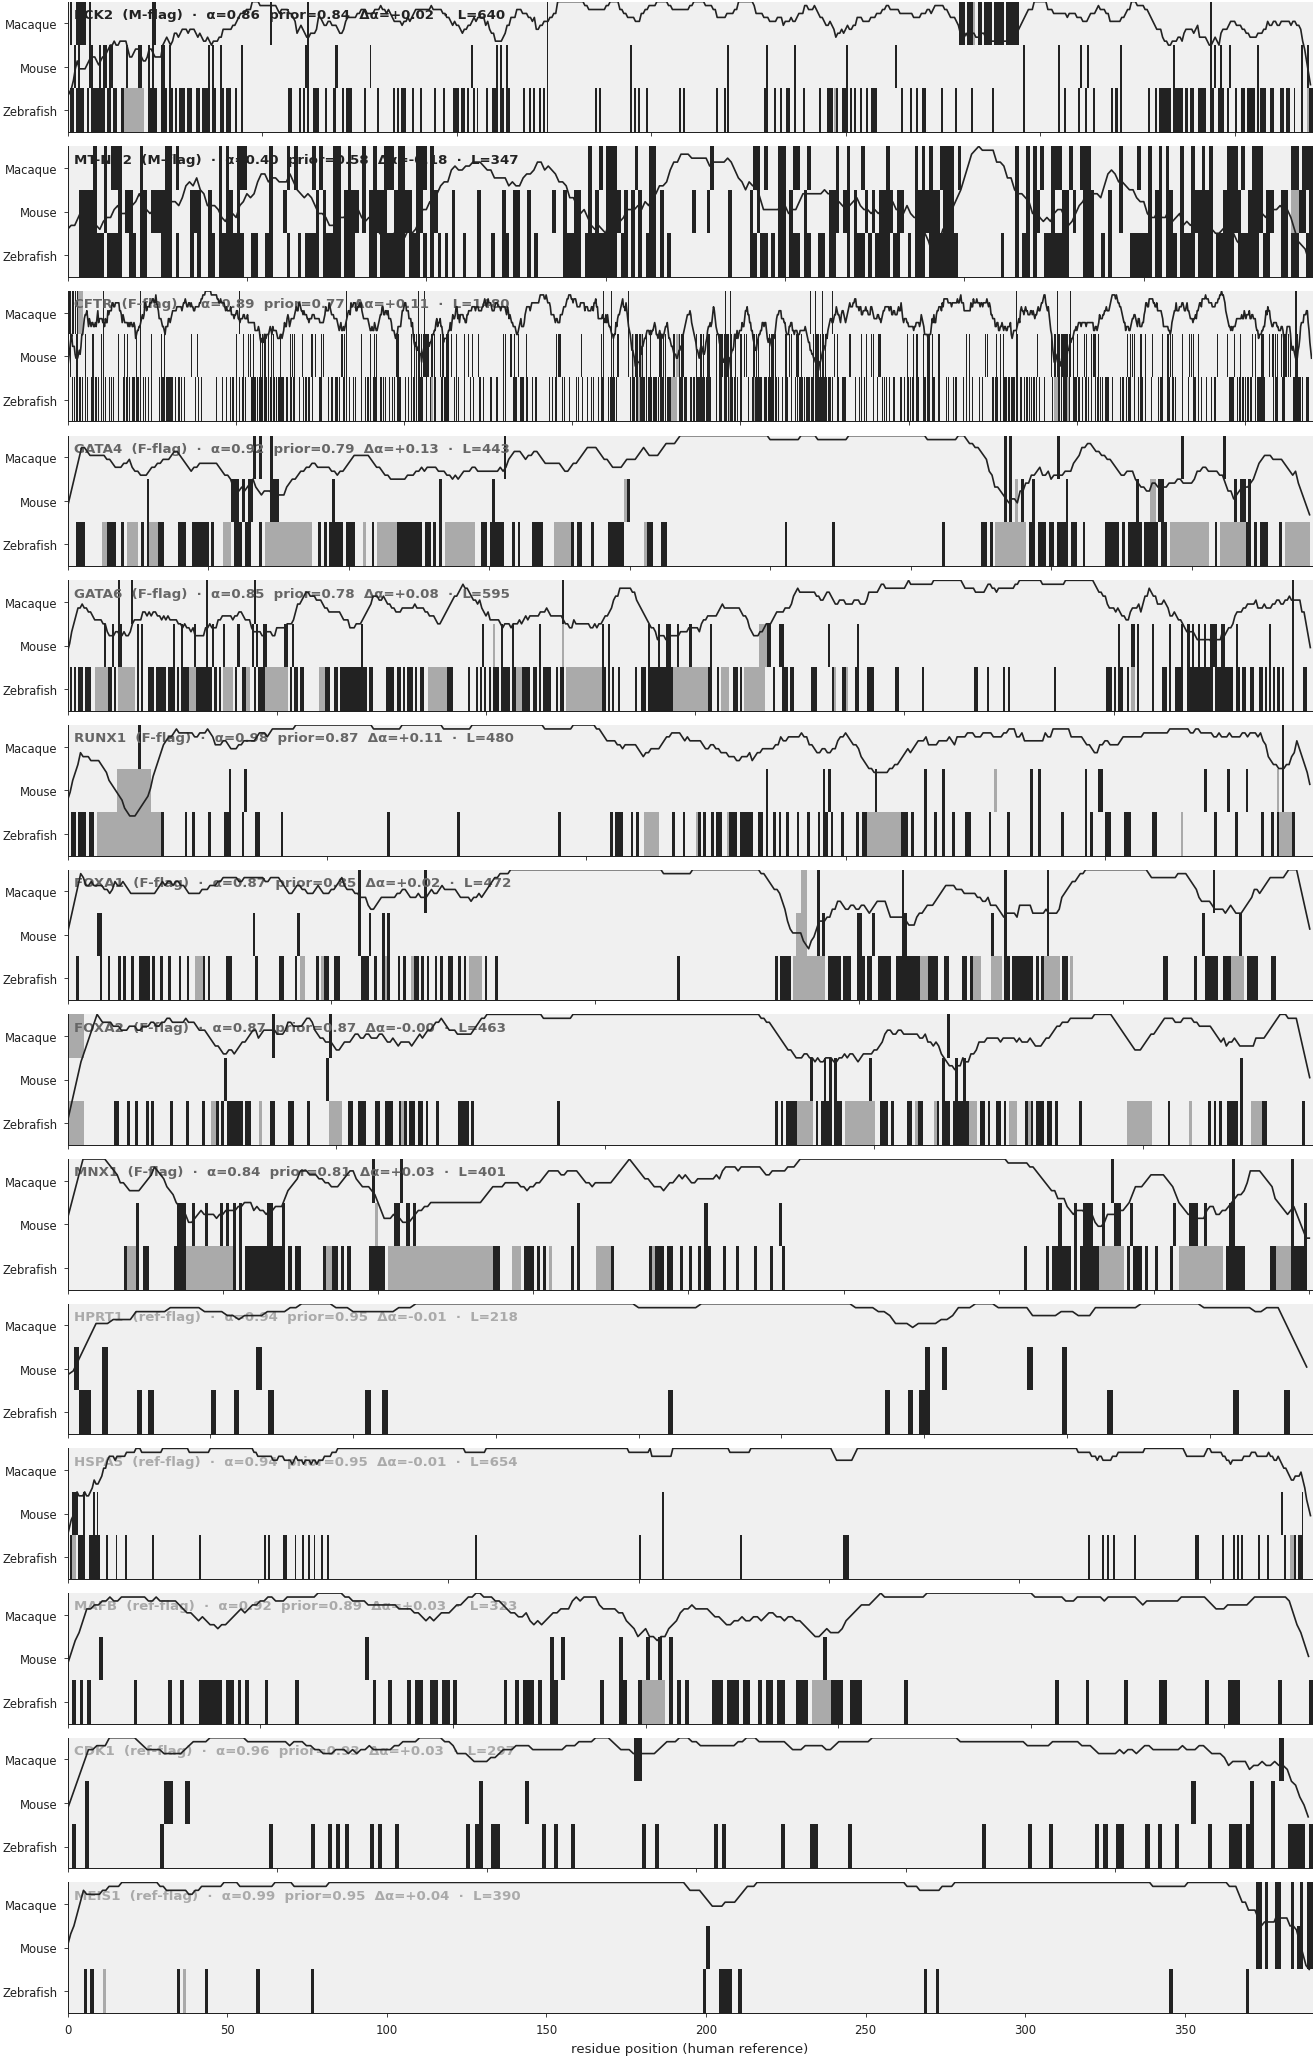

In [10]:
valid = [(g, dirn, ds, note) for (g, dirn, ds, note) in GENES
         if g in GENE_RECORDS and g in PROJECTIONS]
n = len(valid)
if n:
    fig, axes = plt.subplots(n, 1, figsize=(11.0, 1.20 * n + 0.4),
                              constrained_layout=True)
    if n == 1: axes = [axes]
    from matplotlib.colors import ListedColormap
    cmap = ListedColormap([GRAY_LITE, GRAY_DARK, GRAY_BG])  # gap, mismatch, match
    for ax, (g, dirn, ds, note) in zip(axes, valid):
        proj = PROJECTIONS[g]
        sig = SIGNAL.loc[g]
        L = proj["length"]
        # Build (4, L) image: row 0 = mean (continuous); rows 1-3 = species
        mean_match = proj["mean_match"]
        rows = [proj["per_species"][s] for s in SPECIES_NON_HUMAN]
        img = np.vstack(rows).astype(float)
        img_idx = (img + 1).astype(int)
        # split: render mean as a colorbar strip on top
        ax.imshow(img_idx, aspect="auto", cmap=cmap, vmin=0, vmax=2,
                   interpolation="nearest", extent=[0, L, 0, len(rows)])
        # overlay smoothed mean as a curve on top
        ax2 = ax.twinx()
        kernel = np.ones(11) / 11.0
        sm = np.convolve(mean_match, kernel, mode="same") if L >= 11 else mean_match
        ax2.plot(np.arange(L), sm, color="#222222", linewidth=1.0)
        ax2.set_ylim(0, 1.0); ax2.set_yticks([])
        ax2.spines["top"].set_visible(False)
        ax2.spines["right"].set_visible(False)
        ax2.spines["left"].set_visible(False)
        ax.set_yticks([0.5, 1.5, 2.5])
        ax.set_yticklabels([SPECIES_LABEL[s] for s in SPECIES_NON_HUMAN[::-1]],
                            fontsize=7)
        # adjust: imshow extent reverses rows; align
        ax.set_yticks(np.arange(len(rows)) + 0.5)
        ax.set_yticklabels([SPECIES_LABEL[s] for s in SPECIES_NON_HUMAN[::-1]],
                            fontsize=7)
        ax.set_xlim(0, L)
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        color = DIRECTION_COLOR.get(dirn, '#222222')
        label = (f"{g}  ({dirn}-flag)  ·  α={sig['alpha']:.2f}  "
                 f"prior={sig['prior']:.2f}  Δα={sig['delta_alpha']:+.2f}  "
                 f"·  L={L}")
        ax.text(0.005, 0.95, label, transform=ax.transAxes,
                 ha="left", va="top", fontsize=8, color=color, fontweight="bold")
        if ax is axes[-1]:
            ax.set_xlabel("residue position (human reference)")
        else:
            ax.tick_params(labelbottom=False)
    fd.save_figure(fig, "G_compare_all_genes")
    plt.show()


# §H — What this teaches us about Chimera

Three things the structure-level view delivers that the gene-level
α / Δα number alone cannot:

1. **Where on the protein the divergence sits.** A gene with
   `mean prior = 0.85` looks identical to a gene with the same
   prior at the gene level — but their per-residue tracks
   can be wildly different. *Steady* low-level divergence (fast
   evolutionary clock) is biologically very different from
   *focal* divergence (a fast-evolving regulatory loop on a
   conserved core). Chimera's gene-level α tags both as "high
   prior, low α" if the model can't reconstruct expression, but
   only this view distinguishes them.

2. **The structural location of disagreement.** When mismatches
   cluster at the **protein surface / disordered termini**, the
   gene is a regulatory-rewiring candidate (the divergent
   residues touch other proteins, signals, modifications). When
   they cluster in the **catalytic / hydrophobic core**, the gene
   is a paralog-collapse candidate (the divergent residues
   affect protein function itself — no functional ortholog
   relationship). The 3D rendering in §F is the read-out for
   this distinction.

3. **A sanity check on the Chimera signal.** Any near-diagonal
   reference genes that survive the §B.2 ESM-2-PC-fraction filter
   should still show roughly uniform conservation along the
   protein — if they don't, the visualization pipeline is broken
   before any biological claim is made on M / F flagged genes.
   (Most pure housekeeping genes — *GAPDH*, *ACTB*, *HPRT1* — do
   *not* survive the ≥ 40 % ESM-2-PC filter, by design: their
   Chimera call is driven by expression statistics, not protein-
   language signal.)

## How to read the figures

- **M-flag genes** (mostly metabolic enzymes, mtDNA-encoded
  OXPHOS subunits, urea-cycle / amino-acid catabolism enzymes).
  Expected pattern: a tightly conserved catalytic core (often a
  Rossmann fold, BH4-binding pocket, or kinase domain) with
  one species disagreeing on a regulatory loop or a flexible
  domain interface. The §F 3D view localizes the disagreement.
- **F-flag genes** (developmental / pancreatic transcription
  factors, receptor tyrosine kinases). Expected pattern: a
  tightly conserved DNA-binding or kinase domain with
  strong divergence on flanking unstructured regions
  (transactivation domains, regulatory tails). The shared
  decoder reconstructs expression anyway — divergence sits on
  protein regions whose sequence drift is decoupled from
  function.
- **Reference genes** (cytoskeletal / chaperone / cell-cycle
  machinery — when surviving the §B.2 filter): near-flat
  conservation along the entire protein.

## How this connects to the Chimera deliverables

`α` and `Δα` are gene-level summaries of the protein-sequence
information that the GIN sees. The protein-sequence structure
view in this notebook is a **window into the
dimensions-collapsed-to-one-number summary**. For each gene
flagged by the §08 QC machinery, the reader can now look at
*where* the divergence sits and decide independently of the
Chimera tag whether the "M flag" is regulatory (surface,
disordered, signaling adapter regions) or functional (active
site, hydrophobic core, fold-determining residues). That
extra level of interpretability is the kind of validation a
cross-species single-cell paper needs to land an α / Δα story
convincingly.


In [11]:
written_pdf = sorted(FIG_DIR.glob("*.pdf"))
written_html = sorted(HTML_DIR.glob("*.html"))
print(f"\n{len(written_pdf)} PDF figures in {FIG_DIR}:")
for p in written_pdf:
    print(f"  {p.name:50s} {p.stat().st_size/1024:6.1f} KB")
print(f"\n{len(written_html)} 3D HTML embeds in {HTML_DIR}:")
for p in written_html:
    print(f"  {p.name:30s} {p.stat().st_size/1024:6.1f} KB")



15 PDF figures in /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/protein_structure:
  e_track__cdk1.pdf                                    23.6 KB
  e_track__cftr.pdf                                    43.2 KB
  e_track__foxa1.pdf                                   26.6 KB
  e_track__foxa2.pdf                                   26.6 KB
  e_track__gata4.pdf                                   26.3 KB
  e_track__gata6.pdf                                   28.2 KB
  e_track__hprt1.pdf                                   22.8 KB
  e_track__hspa5.pdf                                   28.0 KB
  e_track__mafb.pdf                                    24.4 KB
  e_track__meis1.pdf                                   24.8 KB
  e_track__mnx1.pdf                                    25.9 KB
  e_track__mt-nd2.pdf                                  25.7 KB
  e_track__pck2.pdf                                    28.1 KB
  e_track__runx1.pdf                                   26.2 KB
  g_compa